In [1]:
from skimage.io import imread
from skimage.transform import resize
import numpy as np
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense

In [2]:
import os

In [3]:
train_data="C:\\Users\\mylen\\Desktop\\desktop\\deeplearning\\braintumor\\Training"
X_train=[]
y_train=[]

categories=os.listdir(train_data)
categories

['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']

In [4]:
for category in categories:
  cat_path=os.path.join(train_data,category)
  #print(cat_path)
  images=os.listdir(cat_path)
  #print(images)
  for image in images:
    img_path=os.path.join(cat_path,image)
    #print(img_path)
    img=imread(img_path)
    img_res=resize(img,(150,150,1))

    X_train.append(img_res)
    y_train.append(categories.index(category))

  print("data loaded......")





data loaded......
data loaded......
data loaded......
data loaded......


In [5]:
len(X_train),len(y_train)

(1656, 1656)

In [6]:
test_data="C:\\Users\\mylen\\Desktop\\desktop\\deeplearning\\braintumor\\Testing"
X_test=[]
y_test=[]

for category in categories:
  cat_path=os.path.join(test_data,category)
  #print(cat_path)
  images=os.listdir(cat_path)
  #print(images)
  for image in images:
    img_path=os.path.join(cat_path,image)
    #print(img_path)
    img=imread(img_path)
    img_res=resize(img,(150,150,1))

    X_test.append(img_res)
    y_test.append(categories.index(category))

  print(category,"data loaded......")



glioma_tumor data loaded......
meningioma_tumor data loaded......
no_tumor data loaded......
pituitary_tumor data loaded......


In [7]:
len(X_train),len(y_train)

(1656, 1656)

In [8]:
len(X_test),len(y_test)

(21, 21)

In [9]:
X_train=np.array(X_train)
y_train=np.array(y_train)
X_test=np.array(X_test)
y_test=np.array(y_test)

In [10]:
model=Sequential()

In [11]:
model.add(Conv2D(32,(3,3),input_shape=(150,150,1),activation='relu'))
model.add(MaxPool2D(2,2))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(4,activation='softmax'))

c:\Users\mylen\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [13]:
model.fit(X_train,y_train,epochs=10,batch_size=12)

Epoch 1/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 43s 302ms/step - accuracy: 0.6890 - loss: 0.6163
Epoch 2/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 40s 291ms/step - accuracy: 0.9028 - loss: 0.2550
Epoch 3/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 40s 290ms/step - accuracy: 0.9740 - loss: 0.0969
Epoch 4/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 39s 281ms/step - accuracy: 0.9934 - loss: 0.0431
Epoch 5/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 38s 278ms/step - accuracy: 0.9946 - loss: 0.0213
Epoch 6/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 50s 359ms/step - accuracy: 1.0000 - loss: 0.0065
Epoch 7/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 49s 357ms/step - accuracy: 1.0000 - loss: 0.0022
Epoch 8/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 48s 349ms/step - accuracy: 1.0000 - loss: 0.0012
Epoch 9/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 4439s 32s/step - accuracy: 1.0000 - loss: 7.7200e-04
Epoch 10/10
138/138 ━━━━━━━━━━━━━━━━━━━━ 50s 356ms/step - accuracy: 1.0000 - loss: 5.6251e-04


In [14]:
model.evaluate(X_test,y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.2857 - loss: 11.7625


[11.762492179870605, 0.2857142984867096]

In [15]:
model.save("brain_tumor_cnnmodel.keras") #keras,h5

In [16]:
y_pred=model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step


In [17]:
y_pred

array([[3.3280103e-09, 1.0000000e+00, 6.1738537e-13, 1.4462758e-15],
       [1.4700986e-06, 9.9999845e-01, 1.1885113e-07, 1.7976372e-09],
       [5.7116413e-01, 4.2763087e-01, 1.0655497e-03, 1.3944211e-04],
       [2.9913010e-02, 9.7008687e-01, 7.9044483e-08, 5.2827773e-09],
       [9.4028718e-10, 1.0000000e+00, 2.2524339e-12, 9.3841798e-15],
       [5.7116413e-01, 4.2763087e-01, 1.0655497e-03, 1.3944211e-04],
       [2.3226032e-03, 9.9767739e-01, 1.5538767e-09, 2.9963785e-11],
       [2.1220014e-11, 1.0000000e+00, 3.1113956e-14, 6.8058580e-19],
       [4.2099873e-06, 9.9999511e-01, 6.4767119e-07, 7.8963303e-10],
       [1.6178193e-03, 9.9838221e-01, 1.4380430e-08, 5.4885128e-09],
       [1.2162435e-06, 9.9999881e-01, 3.4826555e-09, 2.3821568e-12],
       [3.2675283e-03, 9.9673247e-01, 7.2614959e-08, 6.9793997e-11],
       [4.0362316e-05, 9.9995959e-01, 1.0652256e-11, 4.1752839e-14],
       [1.5024670e-05, 9.9998260e-01, 2.3339994e-06, 1.7111369e-09],
       [9.9589819e-01, 4.1009560e-

In [18]:
y_pred1=y_pred.argmax(axis=1)
y_pred1

array([1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1])

In [19]:
y_test

array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3])

In [20]:
from sklearn.metrics import classification_report
print(classification_report(y_pred1,y_test))

              precision    recall  f1-score   support

           0       0.29      0.40      0.33         5
           1       1.00      0.25      0.40        16
           2       0.00      0.00      0.00         0
           3       0.00      0.00      0.00         0

    accuracy                           0.29        21
   macro avg       0.32      0.16      0.18        21
weighted avg       0.83      0.29      0.38        21



c:\Users\mylen\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\mylen\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\mylen\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

In [21]:
img1="braintumor/Testing/glioma_tumor/image(1).jpg"
img12=imread(img1)
img12

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(619, 495, 3), dtype=uint8)

In [22]:
img_resize=resize(img12,(150,150,1))

In [23]:
img_resize.shape

(150, 150, 1)

In [24]:
X_train.shape

(1656, 150, 150, 1)

In [25]:
#(1, 150, 150, 1)
img123=img_resize.reshape(1,150,150,1)

In [26]:
y=model.predict(img123)
y

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


array([[3.3280421e-09, 1.0000000e+00, 6.1739123e-13, 1.4462868e-15]],
      dtype=float32)

In [27]:
pred=y.argmax()
pred

np.int64(1)

In [28]:
categories[pred]

'meningioma_tumor'

In [29]:
categories[pred]

'meningioma_tumor'

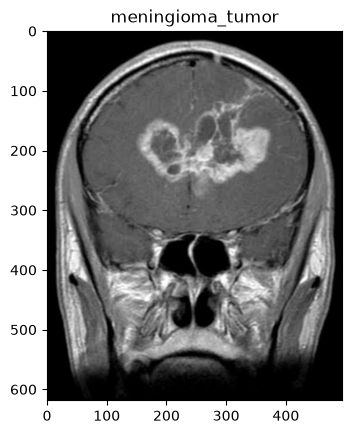

In [30]:
import matplotlib.pyplot as plt
plt.imshow(img12,cmap='gray')
plt.title(categories[pred])
plt.show()

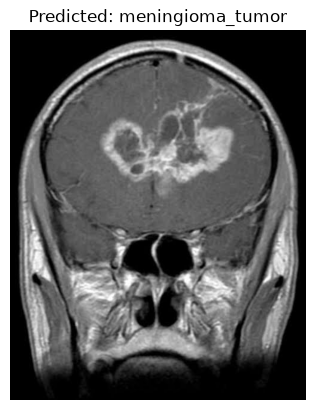

In [31]:
import matplotlib.pyplot as plt

plt.imshow(img12)
plt.title("Predicted: " + categories[pred])
plt.axis("off")
plt.show()